# Image Classification Done Right: VGGNet

In [1]:
# Start downloading the dataset early, since it might take a while.
# If the dataset is already available at the path passed to "root", it won't be
# downloaded again
#import torchvision
#_ = torchvision.datasets.CIFAR10(root='./data', train=True,
#                                        download=True)
#_ = torchvision.datasets.CIFAR10(root='./data', train=False,
#                                        download=True)

In [2]:
import torchvision

# Download the original CIFAR-10 archive from a mirror.
torchvision.datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

# Download and extract both training and test data.
# Before you ask: even though you see "train=True", it will still download
# the entire dataset. The split only decides which data will be sampled and
# stored in the variable "_" once the dataset is fully downloaded.
_ = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True
)

100%|██████████| 170M/170M [00:03<00:00, 51.0MB/s]


## VGGNet configurations

We are going to implement VGGNet in some of its most popular configurations. The implementation strives to be simple and clear to understand.

Let's take a look at the architecture description given by the authors in the [paper](https://arxiv.org/abs/1409.1556):

<img src="./img/vggnet_arch_paper.png" alt="VGGNet architecture described in the paper" width="640"/>

The paper also includes a handy table where each variant is "exploded", so we can see the layer sequence:

<img src="./img/vggnet_arch_table.png" alt="Table with VGGNet architectures." width="640"/>

### Core components

By reading the paper's description, we can already sketch out the core structure of VGGNet. For the sake of simplicity, we are going to leave out from our implementation both the "LRN" and the $1 \times 1$ conv variants. Our targets will be configurations **A**, **B**, **D**, **E**.

The core components are:

- $2\text{D}$ convolutions with $3 \times 3$ kernels, stride $1$ and padding that preserves spatial dimensions, each followed by **ReLU non-linearity**
- max-pooling layers with $2 \times 2$ windows and stride $2$ (stride is what downsamples the feature maps' spatial dimensions)

One detail you can find in Section 3.1 is that **dropout regularization** is applied for the first two fully-connected layers, with dropout probability $p = 0.5$.

Since _all_ hidden layers are equipped with ReLU non-linearity, we need to apply it **after fully connected layers too**!

Let's start by defining our set of configurations. We will represent the network as a plain list of modules. To configure each module, we will represent it with one configuration parameter entry in our list.

1. Integers will represent the **output channels** of a convolutional layer, e.g. `64` will represent "a $3 \times 3$ convolution with $64$ output channels
2. the string `max_pool` will represent a max-pooling layer

> **You may ask**: how do we set the number of input channels for each conv layer? Since the input channels must agree with the previous' conv output channels, we will just use the latter. This is an architectural constraint, the network cannot function if it's not respected!

### Small adaptations

Note that the original implementation expects images of shape $224 \times 224$, which is the ImageNet standard. In this notebook we will train a VGGNet from scratch using the CIFAR-10 dataset, whose images have shape $32 \times 32$.

**Does this break VGGNet?** Changing the image shape does not strictly break the convolution + max-pooling stack of layers, since those can work on channels of arbitrary size. What would break is the **interface between the convolutional backbone and the classifier head**: just before the first fully-connected layer, we _flatten_ the feature map into a vector and feed it to the linear layer. Changing the size of the input image will change the size of the last feature maps that gets flattented: a larger input image translates to a larger feature map given the same downsampling schedule, which then translates to a longer vector.

There are various ways to solve this problem:

- swapping the last max-pool layer (the one preceding the first $\text{FC 4096}$) with a **adaptive average-pool layer**, which returns a fixed-size feature map obtained via average pooling regardless of the spatial dimensions of its input
- resizing the input image to $224 \times 224$ using some kind of interpolation strategy


torchvision implmentation [here](https://docs.pytorch.org/vision/main/_modules/torchvision/models/vgg.html#vgg16_bn:~:text=class-,VGG) for reference.

In [ ]:
import torch
import torch.nn as nn

_vggnet_configs = {
    "vgg11": [64, "max_pool", 128, "max_pool", 256, 256, "max_pool", 512, 512, "max_pool", 512, 512],
}
class VGGNet(nn.Module):

    def __init__(self, config: list[int | str], in_channels: int = 3, num_classes: int = 1000, batch_norm = False, dropout = 0.5):
        # You should always call this super() constructor,
        # otherwise the instance won't be correctly initialized
        # (and you will get errors!)
        super().__init__()

        # plese, visit https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html

        # let's build the conv backbone:
        # we will populate a list of layers
        # defined by the config
        in_ch = in_channels
        backbone_layers = []
        for layer in config:
            # we check if the layer is max pool or conv
            # by differentiating str and int objects
            if layer == "max_pool":
                # max-pool will have stride=2 but no padding,
                # which downsamples feature maps
                backbone_layers.append(
                    nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                out_ch = layer
                # padding=1 and default stride=1
                # preserve spatial dimensions
                conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
                backbone_layers.append(conv)

                if batch_norm:
                    # follow conv with batch-normalization
                    backbone_layers.append(nn.BatchNorm2d(out_ch))

                # relu after conv, as per original recipe
                backbone_layers.append(nn.ReLU(inplace=True))

                in_ch = out_ch

        self.conv_backbone = nn.Sequential(
            *backbone_layers
        )

        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # use "in_ch"'s last set value to get the number of feature maps
        self.classifier = nn.Sequential(
            nn.Linear(in_ch * 7 * 7, 4096), # first fc-4096
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(4096, 4096), # second fc-4096
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(4096, num_classes) # final classifier head
        )

    def forward(self, x):
        x = self.conv_backbone(x)
        x = self.avgpool(x)
        x = x.flatten(1)
        x = self.classifier(x)
        return x

## Number of parameters

The paper reports the number of parameters for each configuration (see the image above). Let's try to compute them.

The modules that have parameters we need to count are the following:

1. `Conv2d`: a conv of shape $(C_{\text{out}}, C_{\text{in}}, K, K)$ has its `weight` parameter of size $C_{\text{out}} \cdot C_{\text{in}} \cdot K \cdot K$ and `bias` of size $C_{\text{out}}$
2. `Linear`: `weight` of size $C_{\text{out}} \cdot C_{\text{in}}$, `bias` of size $C_{\text{out}}$
3. `BatchNorm2d`: `weight` and `bias` both have $C_{\text{out}}$ parameters

In [5]:
def count_parameters(vgg_model: nn.Module):
    conv_params = 0
    linear_params = 0
    bn_params = 0
    # cycle all the modules with their names
    for name, mod in vgg_model.named_modules():
        params = 0
        if isinstance(mod, nn.Conv2d):
            params = mod.weight.numel() + (mod.bias.numel() if mod.bias is not None else 0)
            conv_params = conv_params + params
        elif isinstance(mod, nn.Linear):
            params = mod.weight.numel() + (mod.bias.numel() if mod.bias is not None else 0)
            linear_params = linear_params + params
        elif isinstance(mod, nn.BatchNorm2d):
            if mod.affine:
                params = mod.weight.numel() + mod.bias.numel()
                bn_params = bn_params + params

        if params != 0:
            print(f"{name} -> {params}")

    return {
        "total": conv_params + linear_params + bn_params,
        "conv": conv_params,
        "linear": linear_params,
        "bn": bn_params
    }

In [6]:
net = VGGNet(_vggnet_configs["vgg11"], num_classes=10, batch_norm=True)
params = count_parameters(net)

tot_params = params["total"]
conv_params = params["conv"]
linear_params = params["linear"]
bn_params = params["bn"]

print(
    f"""--- VGG11 params ---
Total: {tot_params}
Conv: {conv_params} ({100 * conv_params / tot_params:.2f}% of total)
Linear: {linear_params} ({100 * linear_params / tot_params:.2f}% of total)
BatchNorm: {bn_params} ({100 * bn_params / tot_params:.8f}% of total)
"""
)

conv_backbone.0 -> 1792
conv_backbone.1 -> 128
conv_backbone.4 -> 73856
conv_backbone.5 -> 256
conv_backbone.8 -> 295168
conv_backbone.9 -> 512
conv_backbone.11 -> 590080
conv_backbone.12 -> 512
conv_backbone.15 -> 1180160
conv_backbone.16 -> 1024
conv_backbone.18 -> 2359808
conv_backbone.19 -> 1024
conv_backbone.22 -> 2359808
conv_backbone.23 -> 1024
conv_backbone.25 -> 2359808
conv_backbone.26 -> 1024
classifier.0 -> 102764544
classifier.3 -> 16781312
classifier.6 -> 40970
--- VGG11 params ---
Total: 128812810
Conv: 9220480 (7.16% of total)
Linear: 119586826 (92.84% of total)
BatchNorm: 5504 (0.00427287% of total)



Do the parameter counts respect what we think they should be? Let's suppose we have in input images with 3 channels, and they are 224x224 big, therefore the input tensor has shape [224, 224,3]

In [7]:
print(net.state_dict().keys())

conv_layers_weights = []
conv_layers_biases = []
for key, module in net.named_modules():
  # print(key, type(module))#, module.shape, module.numel())
  if isinstance(module, nn.Conv2d):
    for key, value in module.state_dict().items():
      if "weight" in key:
        conv_layers_weights.append(value)
        print(f"Adding to WEIGHTS {key} which has {value.numel()} parameters.")
      elif "bias" in key:
        conv_layers_biases.append(value)
        print(f"Adding to BIASES {key} which has {value.numel()} parameters.")

odict_keys(['conv_backbone.0.weight', 'conv_backbone.0.bias', 'conv_backbone.1.weight', 'conv_backbone.1.bias', 'conv_backbone.1.running_mean', 'conv_backbone.1.running_var', 'conv_backbone.1.num_batches_tracked', 'conv_backbone.4.weight', 'conv_backbone.4.bias', 'conv_backbone.5.weight', 'conv_backbone.5.bias', 'conv_backbone.5.running_mean', 'conv_backbone.5.running_var', 'conv_backbone.5.num_batches_tracked', 'conv_backbone.8.weight', 'conv_backbone.8.bias', 'conv_backbone.9.weight', 'conv_backbone.9.bias', 'conv_backbone.9.running_mean', 'conv_backbone.9.running_var', 'conv_backbone.9.num_batches_tracked', 'conv_backbone.11.weight', 'conv_backbone.11.bias', 'conv_backbone.12.weight', 'conv_backbone.12.bias', 'conv_backbone.12.running_mean', 'conv_backbone.12.running_var', 'conv_backbone.12.num_batches_tracked', 'conv_backbone.15.weight', 'conv_backbone.15.bias', 'conv_backbone.16.weight', 'conv_backbone.16.bias', 'conv_backbone.16.running_mean', 'conv_backbone.16.running_var', 'con

In [8]:
_vggnet_configs["vgg11"]
previous_channels = 3
kernel_size = 3
iteration = 0
for el in _vggnet_configs["vgg11"]:
  if isinstance(el, int):
    next_channels = el
    # formula for the number of parameters in a convolutional layer:
    number_of_parameters_weight = previous_channels * kernel_size * kernel_size * next_channels
    number_bias = next_channels
    total_params = number_of_parameters_weight + number_bias
    actual_params = conv_layers_weights[iteration].numel() + conv_layers_biases[iteration].numel()
    print(f"Conv n°{iteration+1}: computed params: {total_params} \tActual params: {actual_params}")
    iteration += 1
    previous_channels = next_channels


Conv n°1: computed params: 1792 	Actual params: 1792
Conv n°2: computed params: 73856 	Actual params: 73856
Conv n°3: computed params: 295168 	Actual params: 295168
Conv n°4: computed params: 590080 	Actual params: 590080
Conv n°5: computed params: 1180160 	Actual params: 1180160
Conv n°6: computed params: 2359808 	Actual params: 2359808
Conv n°7: computed params: 2359808 	Actual params: 2359808
Conv n°8: computed params: 2359808 	Actual params: 2359808


# Forward Pass Debug
If it can process random data, then you're mostly alright :D

In [9]:
import numpy as np

num_params = sum([np.prod(p.shape) for p in net.parameters()])
print(f"Number of parameters : {num_params}")
print("-"*50)

# Test on ImageNet-like shaped data

X = torch.rand((8, 3, 224, 224))  # B, C, H, W
print('Output shape for ImageNet:', net(X).shape)

Number of parameters : 128812810
--------------------------------------------------
Output shape for ImageNet: torch.Size([8, 10])


In [10]:
# Test on CIFAR-like shaped data

X = torch.rand((8, 3, 32, 32))
print('Output shape for CIFAR-10:', net(X).shape)

Output shape for CIFAR-10: torch.Size([8, 10])


# Let's train on CIFAR-10

In [11]:
import torchvision
import torchvision.transforms.v2 as transforms

mean = (0.4913997551666284, 0.48215855929893703, 0.4465309133731618)
std  = (0.24703225141799082, 0.24348516474564, 0.26158783926049628)

base = [
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean, std)
]
flip_jitter = [
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
]
resize = transforms.Resize(256, interpolation=transforms.InterpolationMode.BILINEAR)

# (train, test) transforms for each setup
transform_setups = {
    "base": (base, base),
    "flip_jitter": (flip_jitter + base, base),
    "resize_crop_flip_jitter": (
        [resize, transforms.RandomCrop(224)] + flip_jitter + base,
        [resize, transforms.CenterCrop(224)] + base,
    ),
}
setup = "base"
train_tf, test_tf = transform_setups[setup]
transform = transforms.Compose(train_tf)
test_transform = transforms.Compose(test_tf)

# Carve a validation split out of the training set; it uses the test-time transform
val_size = 5000
full_train = torchvision.datasets.CIFAR10(root='./data', train=True,
                                          download=True, transform=transform)
full_train_eval = torchvision.datasets.CIFAR10(root='./data', train=True,
                                               download=True, transform=test_transform)
perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(0)).tolist()
trainset = torch.utils.data.Subset(full_train, perm[val_size:])
valset = torch.utils.data.Subset(full_train_eval, perm[:val_size])
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64,
                                          shuffle=True, num_workers=2)
valloader = torch.utils.data.DataLoader(valset, batch_size=64,
                                        shuffle=False, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=test_transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64,
                                         shuffle=False, num_workers=2)
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

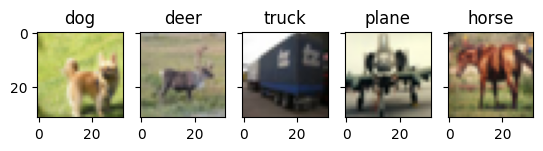

In [12]:
import matplotlib.pyplot as plt

# get some random training images
n_imgs = 5
images, labels = next(iter(trainloader))
images, labels = images[:n_imgs], labels[:n_imgs]

# print(images.shape)

fig, ax = plt.subplots(1, n_imgs, sharey=True)

for i in range(n_imgs):
    # denormalize
    img = images[i] * torch.tensor(std).reshape(-1, 1, 1) + torch.tensor(mean).reshape(-1, 1, 1)
    ax[i].imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax[i].set_title(classes[labels[i]])

plt.show()

In [14]:
assert torch.cuda.is_available(), "Notebook is not configured properly!"
device = 'cuda:0'

net = VGGNet(_vggnet_configs["vgg16"], num_classes=10, batch_norm=True).to(device)

# Nothing works w/o proper initialization
def initialize_weights(model):
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01)
            nn.init.constant_(m.bias, 0)

initialize_weights(net)
crit = nn.CrossEntropyLoss()
opt = torch.optim.SGD(net.parameters(), lr=1e-2, momentum=0.9, weight_decay=5e-4)
epochs = 5
scheduler_name = "plateau"  # "plateau" or "onecycle" or "constant"
if scheduler_name == "plateau":
    # Divide lr by 10 when validation accuracy stops improving (stepped once per epoch).
    # min_lr=1e-5: at most 3 drops, as in the paper; once reached, early stopping can trigger.
    # threshold=0: any increase counts as improvement, same criterion as checkpointing/early stopping
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.1, patience=1, threshold=0, min_lr=1e-5)
elif scheduler_name == "onecycle":
    # Stepped once per batch
    scheduler = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.01, epochs=epochs, steps_per_epoch=len(trainloader))
else: # no scheduler
    scheduler = torch.optim.lr_scheduler.ConstantLR(opt, factor=1.0, total_iters=epochs)
print(f"You\'re running this code on a {torch.cuda.get_device_name()} gpu.")

You're running this code on a Tesla T4 gpu.


In [15]:
from datetime import datetime
from IPython.display import Image
from tqdm.notebook import tqdm
from IPython.display import clear_output
from time import sleep
import matplotlib.pyplot as plt


losses = []
best_acc = 0.0
# Early stopping: stop after this many epochs without a new best val accuracy (None disables it).
# With ReduceLROnPlateau the count restarts at every lr drop, so each new lr gets a fair chance.
# Keep it larger than the ReduceLROnPlateau patience, or training stops before the first lr drop.
# With OneCycleLR prefer None: the lr only anneals at the end of the schedule, and stopping
# early cuts the run before that low-lr phase.
early_stop_patience = 3
epochs_no_improve = 0
best_ckpt_path = 'best_vgg.pt'

# Important! Net must be in "train" mode, especially if we have modules which
# track batch statistics (like BatchNorm2d)
net.train()

now = datetime.now()
train_name = f'{now.hour}:{now.minute}:{now.second}/'
for e in range(epochs):
    pbar = tqdm(total=len(trainloader), desc=f'Epoch {e} - 0%')
    for i, (x, y) in enumerate(trainloader):
        x, y = x.to(device), y.to(device)
        y_pred = net(x)
        loss = crit(y_pred, y)

        opt.zero_grad()
        loss.backward()
        losses.append(loss.item())

        opt.step()
        if scheduler_name == "onecycle":
            scheduler.step()
        pbar.update(1)
        pbar.set_description(f'Epoch {e + 1} - {round(i/len(trainloader) * 100)}% -- loss {loss.item():.2f}')

    with torch.no_grad():
        corr = 0
        # Now the network should go into "eval" mode
        net.eval()
        # This freezes stats tracking and weights
        for x, y in valloader:
            x, y = x.to(device), y.to(device)
            y_pred = net(x)
            corr += (torch.max(y_pred, 1)[1] == y).sum()
        # Back to training mode
        net.train()
    acc = (corr / len(valset)).item()
    if scheduler_name == "plateau":
        lr_before = opt.param_groups[0]['lr']
        scheduler.step(acc)
        lr_dropped = opt.param_groups[0]['lr'] < lr_before
    else:
        lr_dropped = False
    if acc > best_acc:
        best_acc = acc
        epochs_no_improve = 0
        torch.save(net.state_dict(), best_ckpt_path)
    elif lr_dropped:
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
    print(f"Val accuracy for epoch {e + 1}: {acc * 100:.2f} % (best {best_acc * 100:.2f} %, lr {opt.param_groups[0]['lr']:.0e})")
    if early_stop_patience is not None and epochs_no_improve >= early_stop_patience:
        print(f"Early stopping: no improvement for {early_stop_patience} epochs")
        break

end = datetime.now() - now
print(f"Total training time is : {end}")

Epoch 0 - 0%:   0%|          | 0/704 [00:00<?, ?it/s]

Val accuracy for epoch 1: 52.42 % (best 52.42 %, lr 1e-02)


Epoch 1 - 0%:   0%|          | 0/704 [00:00<?, ?it/s]

Val accuracy for epoch 2: 66.34 % (best 66.34 %, lr 1e-02)


Epoch 2 - 0%:   0%|          | 0/704 [00:00<?, ?it/s]

Val accuracy for epoch 3: 73.70 % (best 73.70 %, lr 1e-02)


Epoch 3 - 0%:   0%|          | 0/704 [00:00<?, ?it/s]

Val accuracy for epoch 4: 76.64 % (best 76.64 %, lr 1e-02)


Epoch 4 - 0%:   0%|          | 0/704 [00:00<?, ?it/s]

Val accuracy for epoch 5: 77.66 % (best 77.66 %, lr 1e-02)
Total training time is : 0:05:03.912350


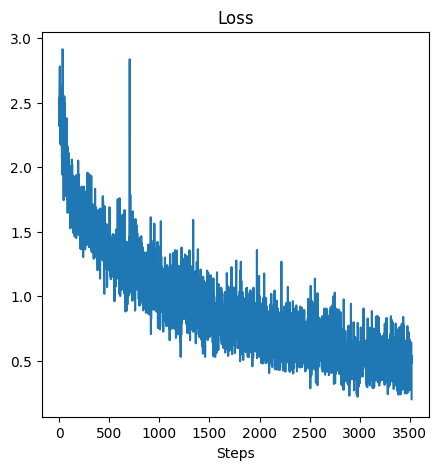

In [16]:
# Let's look at the loss
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.plot(losses)
ax.set_title("Loss")
ax.set_xlabel("Steps")

plt.show()

## Test set evaluation

The test set was never used during training, so we evaluate the best checkpoint (selected on the validation set) on it just once, at the end.

In [20]:
def evaluate(model, loader):
    # eval mode: BatchNorm uses running stats, Dropout is off
    model.eval()
    corr = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            corr += (model(x).argmax(1) == y).sum().item()
    return corr / len(loader.dataset)

# Load the best weights (by validation accuracy) before testing
net.load_state_dict(torch.load(best_ckpt_path))
test_acc = evaluate(net, testloader)
print(f"Test accuracy of best checkpoint: {test_acc * 100:.2f} %")

Test accuracy of best checkpoint: 77.94 %


## Visualizing learned kernels

A conv layer's `weight` has shape $(C_{\text{out}}, C_{\text{in}}, K, K)$: each of the $C_{\text{out}}$ filters is a stack of $C_{\text{in}}$ kernels of size $K \times K$. We lay them out on a grid inside a single image: one row per filter, one column per input channel, with blank (NaN) pixels separating the kernels.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def plot_conv_kernels(conv: nn.Conv2d, max_filters=None, max_in=None, save_path=None, dpi=300):
    # weight shape: (C_out, C_in, K, K); detach from the graph and move to numpy
    w = conv.weight.detach().cpu().numpy()
    # optionally keep only the first filters / input channels (deep layers have 512x512 kernels)
    w = w[:max_filters, :max_in]
    n_out, n_in, kh, kw = w.shape

    # Canvas with one (K+1)x(K+1) cell per kernel: the extra row/column is the separator.
    # Filling with NaN makes the separators "null" pixels that imshow leaves blank.
    canvas = np.full((n_out * (kh + 1) - 1, n_in * (kw + 1) - 1), np.nan)
    for o in range(n_out):          # rows: output filters
        for i in range(n_in):       # columns: input channels of that filter
            r, c = o * (kh + 1), i * (kw + 1)
            canvas[r:r + kh, c:c + kw] = w[o, i]

    # viridis colormap; NaN pixels ("bad" values) are drawn white
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("white")

    # Size the figure with the grid so kernels stay square and readable
    fig, ax = plt.subplots(figsize=(max(4, n_in * 0.4), max(4, n_out * 0.4)))
    # One shared color scale for all kernels, so weight magnitudes are comparable
    # interpolation="none" keeps every weight a sharp square block, also when zooming into a saved file
    # (PNG at high dpi, or PDF/SVG where the image is embedded at native resolution)
    im = ax.matshow(canvas, cmap=cmap, interpolation="none")
    # matshow puts the x ticks on top, so move the x label there too
    ax.set_xlabel("input channel")
    ax.xaxis.set_label_position("top")
    ax.set_ylabel("filter")
    # Ticks at the center of each kernel cell, labelled with its channel/filter index
    ax.set_xticks(np.arange(n_in) * (kw + 1) + (kw - 1) / 2, labels=range(n_in))
    ax.set_yticks(np.arange(n_out) * (kh + 1) + (kh - 1) / 2, labels=range(n_out))
    fig.colorbar(im, ax=ax, label="weight")
    # Save before plt.show(), which may close the figure in notebooks.
    # High dpi gives many screen pixels per weight, so kernels stay inspectable when zoomed.
    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    plt.show()
    return fig

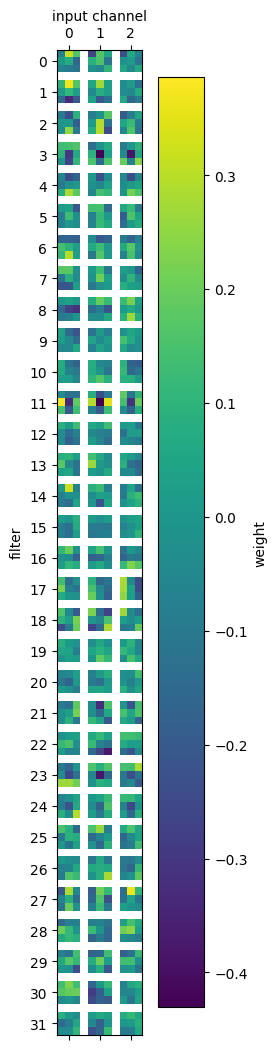

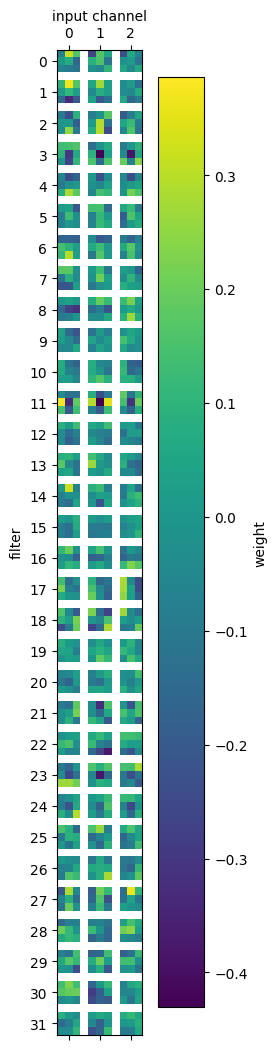

In [18]:
# Load the best checkpoint and pick a conv layer (layer_idx counts Conv2d modules in order)
net.load_state_dict(torch.load(best_ckpt_path))
convs = [m for m in net.modules() if isinstance(m, nn.Conv2d)]
layer_idx = 0
plot_conv_kernels(convs[layer_idx], max_filters=32, max_in=32)

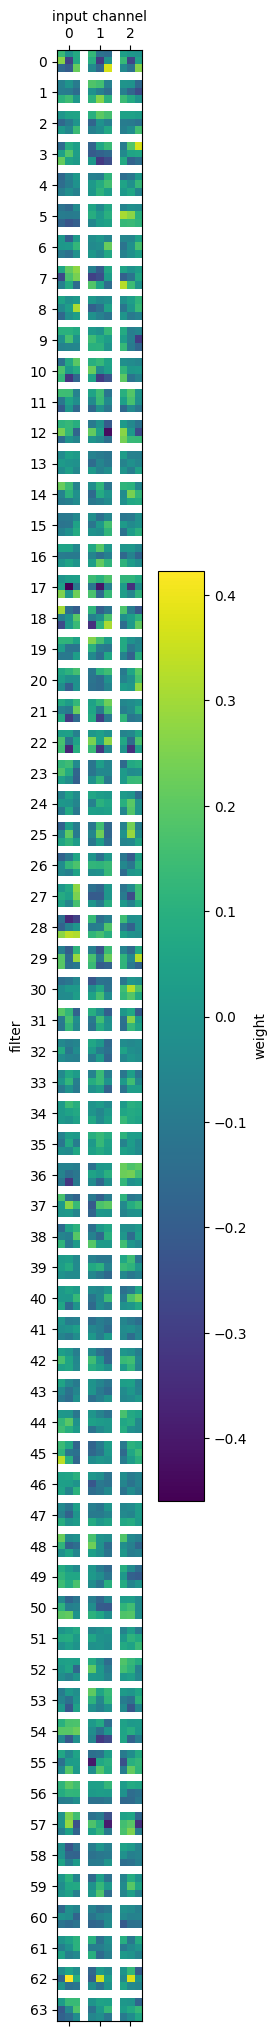

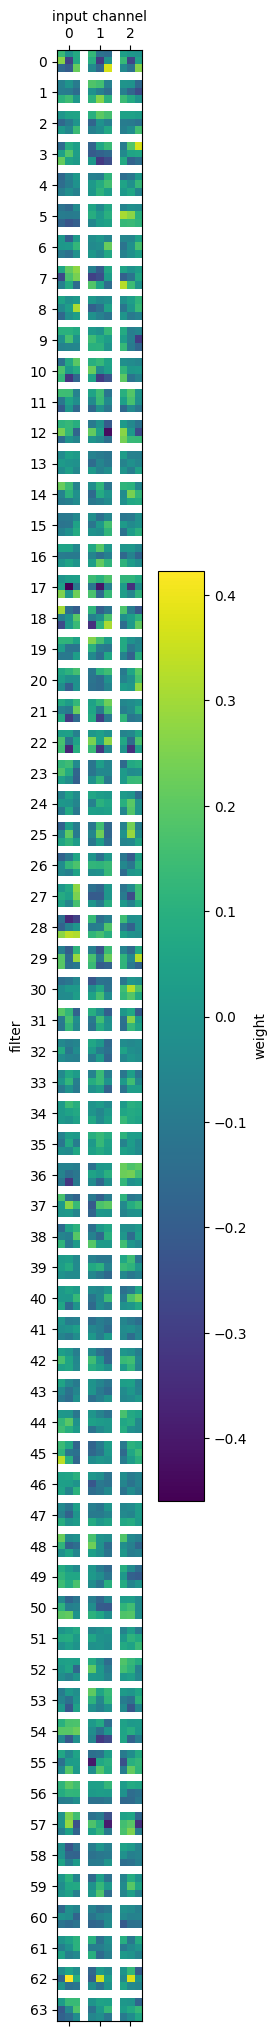

In [ ]:
# Example: save the plot of the first conv layer to the current directory.
# Use a .pdf/.svg extension instead for a vector file that zooms without limits.
plot_conv_kernels(convs[0], save_path="conv0_kernels.png", dpi=300)

# Transfer learning: pretrained ResNet versus VGG from scratch

We now compare the **best validation checkpoint of our VGG-16** with an **ImageNet-pretrained ResNet-18**, using the same CIFAR-10 training/validation indices and test images.

| Experiment | Starting point | Parameters learned on CIFAR-10 |
| --- | --- | --- |
| VGG-16 from scratch | Random initialization | All parameters |
| ResNet-18 linear probe | ImageNet-pretrained backbone + new linear head | Only the 512 → 10 classifier |
| ResNet-18 full fine-tuning | Fresh ImageNet-pretrained model + new linear head | All parameters |

**Linear probing is supervised transfer learning, not zero-shot evaluation.** It measures how useful the pretrained features are when only a linear classifier is allowed to learn. The original ImageNet head predicts 1,000 different classes and cannot directly serve as our CIFAR-10 classifier.

ResNet uses residual connections: a block adds a learned transformation to a shortcut, helping gradients flow through the network. See [He et al., Deep Residual Learning for Image Recognition (CVPR 2016)](https://arxiv.org/abs/1512.03385), the [torchvision ResNet-18 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html), and the [PyTorch transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).

Run the previous cells first, including VGG training and test evaluation. These new cells use separate names and do not replace the earlier training functions.

In [21]:
from pathlib import Path
from time import perf_counter
import random
import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from tqdm.auto import tqdm

required = ('net', 'trainset', 'valset', 'testset', 'test_acc', 'best_acc', 'epochs')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Run the earlier VGG cells first. Missing variables: {missing}")

transfer_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TRANSFER_SEED = 42
PROBE_EPOCHS = 5
FINETUNE_EPOCHS = 5
TRANSFER_BATCH_SIZE = 64
FEATURE_BATCH_SIZE = 256
TRANSFER_WORKERS = 2
PROBE_LR = 0.01
FINETUNE_BACKBONE_LR = 0.001
FINETUNE_HEAD_LR = 0.01

def transfer_seed(seed=TRANSFER_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Preserve the measured VGG result before running new experiments.
vgg_result = {
    'Experiment': 'VGG-16 from scratch',
    'Pretraining': 'None',
    'Trainable parameters': sum(p.numel() for p in net.parameters() if p.requires_grad),
    'Best validation accuracy (%)': 100 * float(best_acc),
    'Test accuracy (%)': 100 * float(test_acc),
    'Epochs run': e + 1,
    'Training seconds': end.total_seconds(),
}
vgg_input_shape = tuple(trainset[0][0].shape)
# Keep the trained VGG accessible while freeing its parameter memory on the GPU.
net.to('cpu')
if transfer_device.type == 'cuda':
    torch.cuda.empty_cache()
print('Transfer-learning device:', transfer_device)
print('VGG input shape:', vgg_input_shape)

Transfer-learning device: cuda
VGG input shape: (3, 32, 32)


## Preprocessing and identical data splits

The pretrained weights come with an inference transform: resize to 256, center-crop to 224×224, convert to a floating-point tensor, and normalize with **ImageNet** statistics. We use this deterministic transform for both experiments, including training, so frozen features can be cached once. We intentionally introduce no extra augmentation in this section.

The VGG keeps its original preprocessing. This is a practical comparison of training recipes, **not an isolated test of architecture or pretraining**: architecture, input resolution, normalization, and optimization differ. Five epochs are a short classroom demonstration, not necessarily converged performance.

We reuse the exact existing split indices, but construct separate dataset objects so the original transforms stay untouched. `download=False` reuses the CIFAR-10 files from the previous cells.

In [22]:
transfer_weights = ResNet18_Weights.IMAGENET1K_V1
transfer_transform = transfer_weights.transforms()
transfer_root = full_train.root

transfer_train_full = torchvision.datasets.CIFAR10(
    root=transfer_root, train=True, download=False, transform=transfer_transform
)
transfer_testset = torchvision.datasets.CIFAR10(
    root=transfer_root, train=False, download=False, transform=transfer_transform
)
transfer_trainset = Subset(transfer_train_full, list(trainset.indices))
transfer_valset = Subset(transfer_train_full, list(valset.indices))
assert set(transfer_trainset.indices).isdisjoint(transfer_valset.indices)
assert transfer_trainset.indices == list(trainset.indices)
assert transfer_valset.indices == list(valset.indices)
assert transfer_testset.targets == testset.targets

# Separate generators make training shuffle reproducible without sharing state.
def transfer_loader(dataset, batch_size=TRANSFER_BATCH_SIZE, shuffle=False):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        num_workers=TRANSFER_WORKERS,
        pin_memory=transfer_device.type == 'cuda',
        generator=torch.Generator().manual_seed(TRANSFER_SEED),
    )

transfer_trainloader = transfer_loader(transfer_trainset, shuffle=True)
transfer_valloader = transfer_loader(transfer_valset)
transfer_testloader = transfer_loader(transfer_testset)
print(transfer_transform)
print('Train / validation / test:',
      len(transfer_trainset), len(transfer_valset), len(transfer_testset))
print('ResNet input shape:', tuple(transfer_trainset[0][0].shape))

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Train / validation / test: 45000 5000 10000
ResNet input shape: (3, 224, 224)


## 1. Linear probing: freeze the feature extractor

After global average pooling, ResNet-18 produces a 512-dimensional vector $h(x)$. We replace the ImageNet classifier with the identity operation and learn only

$$\mathrm{logits}(x)=Wh(x)+b,$$

where $W$ has shape $(10,512)$ and $b$ has shape $(10,)$. This gives **5,130 trainable parameters**.

Two separate controls matter:

- `requires_grad_(False)` freezes backbone parameters.
- `eval()` freezes BatchNorm running statistics and uses the stored ImageNet statistics. It does **not** disable gradients by itself.

With a frozen backbone and deterministic preprocessing, we can extract training and validation features once, store them in CPU memory, and train the small classifier rapidly. Feature extraction still takes time; the first model call also downloads the pretrained weights. Test features are extracted only after model selection.

In [26]:
transfer_seed()
probe_backbone = resnet18(weights=transfer_weights)
probe_feature_dim = probe_backbone.fc.in_features
probe_backbone.fc = nn.Identity()
probe_backbone.requires_grad_(False)
probe_backbone.eval()
probe_backbone.to(transfer_device)

probe_head = nn.Linear(probe_feature_dim, len(classes))
print('Feature dimension:', probe_feature_dim)
print('Trainable head parameters:', sum(p.numel() for p in probe_head.parameters()))
assert sum(p.numel() for p in probe_head.parameters()) == 5130
assert not any(p.requires_grad for p in probe_backbone.parameters())
probe_head.to(transfer_device)

@torch.no_grad()
def transfer_extract_features(backbone, loader, description):
    backbone.eval()
    features, targets = [], []
    for x, y in tqdm(loader, desc=description):
        h = backbone(x.to(transfer_device, non_blocking=True))
        features.append(h.cpu())
        targets.append(y.cpu())
    return TensorDataset(torch.cat(features), torch.cat(targets))

if transfer_device.type == 'cuda':
    torch.cuda.synchronize()
probe_cache_start = perf_counter()
probe_train_features = transfer_extract_features(
    probe_backbone, transfer_loader(transfer_trainset), 'Extract training features'
)
probe_val_features = transfer_extract_features(
    probe_backbone, transfer_valloader, 'Extract validation features'
)
probe_cache_seconds = perf_counter() - probe_cache_start
probe_trainloader = transfer_loader(probe_train_features, FEATURE_BATCH_SIZE, shuffle=True)
probe_valloader = transfer_loader(probe_val_features, FEATURE_BATCH_SIZE)
print(f'Training + validation feature extraction: {probe_cache_seconds:.1f} seconds')

Feature dimension: 512
Trainable head parameters: 5130


Extract training features:   0%|          | 0/704 [00:00<?, ?it/s]

Extract validation features:   0%|          | 0/79 [00:00<?, ?it/s]

Training + validation feature extraction: 110.2 seconds


## Shared training and evaluation helpers

For each ResNet experiment, train with cross-entropy and select the checkpoint with the highest **validation accuracy**. Do not select epochs or learning rates using test accuracy. The helpers report sample-weighted loss and accuracy and restore the best checkpoint before testing.

The linear probe trains a standalone head on cached features. Full fine-tuning trains the complete network on images, so BatchNorm statistics can adapt to CIFAR-10. We use SGD with momentum for both, with a smaller learning rate for pretrained weights during full fine-tuning.

In [27]:
@torch.no_grad()
def transfer_evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for x, y in loader:
        x = x.to(transfer_device, non_blocking=True)
        y = y.to(transfer_device, non_blocking=True)
        logits = model(x)
        loss_sum += nn.functional.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(1) == y).sum().item()
        count += y.numel()
    return {'loss': loss_sum / count, 'accuracy': correct / count}

def transfer_fit(model, train_loader, val_loader, optimizer, n_epochs, title):
    if n_epochs < 1:
        raise ValueError('Choose at least one training epoch.')
    model.to(transfer_device)
    history, best_state, best_val, best_epoch = [], None, -1.0, None
    if transfer_device.type == 'cuda':
        torch.cuda.synchronize()
    start = perf_counter()
    for epoch in range(n_epochs):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f'{title}: epoch {epoch + 1}/{n_epochs}'):
            x = x.to(transfer_device, non_blocking=True)
            y = y.to(transfer_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.numel()
            correct += (logits.detach().argmax(1) == y).sum().item()
            count += y.numel()
        val_metrics = transfer_evaluate(model, val_loader)
        history.append({
            'epoch': epoch + 1,
            'train_loss': loss_sum / count, 'train_accuracy': correct / count,
            'val_loss': val_metrics['loss'], 'val_accuracy': val_metrics['accuracy'],
        })
        if val_metrics['accuracy'] > best_val:
            best_val, best_epoch = val_metrics['accuracy'], epoch + 1
            # Clone tensors: retaining a shallow state_dict would keep changing during training.
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"Train loss: {loss_sum / count:.4f} | "
              f"Val accuracy: {100 * val_metrics['accuracy']:.2f}%")
    if transfer_device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = perf_counter() - start
    model.load_state_dict(best_state)
    model.eval()
    return history, best_val, best_epoch, seconds

In [28]:
probe_head.to(transfer_device)
probe_optimizer = torch.optim.SGD(
    probe_head.parameters(), lr=PROBE_LR, momentum=0.9, weight_decay=5e-4
)
probe_history, probe_best_val, probe_best_epoch, probe_fit_seconds = transfer_fit(
    probe_head, probe_trainloader, probe_valloader, probe_optimizer,
    PROBE_EPOCHS, 'Linear probe'
)
print(f'Best probe checkpoint: epoch {probe_best_epoch}')

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

Linear probe: epoch 1/5:   0%|          | 0/176 [00:00<?, ?it/s]



  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionErrorAssertionError: : can only test a child processcan only test a child process

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py

Train loss: 0.6685 | Val accuracy: 84.60%


Linear probe: epoch 2/5:   0%|          | 0/176 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>    
if w.is_alive():Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        self._shutdown_workers()assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError    : can only test a child processif w.is_alive():

  File "/usr/lib/

... (8 outputs left out)

Train loss: 0.4082 | Val accuracy: 86.02%


Linear probe: epoch 5/5:   0%|          | 0/176 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a43e908d9e0>
    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError    if w.is_alive():: 
can only test a child process  File "/usr/lib/p

Train loss: 0.3971 | Val accuracy: 86.22%
Best probe checkpoint: epoch 5


### Test the selected linear probe

We now extract test features and evaluate the selected head. Combining the backbone and head produces the same predictions directly from images. Save this complete model, including BatchNorm buffers, so it can be reused without the feature cache.

In [29]:
# No subprocesses for either test loader.
clean_testloader = DataLoader(
    transfer_testset,
    batch_size=TRANSFER_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=transfer_device.type == 'cuda',
)

probe_test_features = transfer_extract_features(
    probe_backbone, clean_testloader, 'Extract test features'
)

clean_featureloader = DataLoader(
    probe_test_features,
    batch_size=FEATURE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

probe_test_metrics = transfer_evaluate(
    probe_head, clean_featureloader
)

# probe_test_features = transfer_extract_features(
#     probe_backbone, transfer_testloader, 'Extract test features'
# )
# probe_test_metrics = transfer_evaluate(
#     probe_head, transfer_loader(probe_test_features, FEATURE_BATCH_SIZE)
# )
probe_model = nn.Sequential(probe_backbone, probe_head).eval()
probe_checkpoint_path = 'best_resnet18_linear_probe.pt'
torch.save(probe_model.state_dict(), probe_checkpoint_path)
probe_result = {
    'Experiment': 'ResNet-18 linear probe',
    'Pretraining': 'ImageNet-1K',
    'Trainable parameters': sum(p.numel() for p in probe_model.parameters() if p.requires_grad),
    'Best validation accuracy (%)': 100 * probe_best_val,
    'Test accuracy (%)': 100 * probe_test_metrics['accuracy'],
    'Epochs run': PROBE_EPOCHS,
    'Training seconds': probe_cache_seconds + probe_fit_seconds,
}
print(f"Linear-probe test accuracy: {100 * probe_test_metrics['accuracy']:.2f}%")
# The next experiment needs its own model; keep this one on CPU for reuse.
probe_model.to('cpu')
if transfer_device.type == 'cuda':
    torch.cuda.empty_cache()

Extract test features:   0%|          | 0/157 [00:00<?, ?it/s]

Linear-probe test accuracy: 85.25%


## 2. Full fine-tuning: let every layer adapt

Start again from **fresh ImageNet weights**, not from the fitted linear probe. Replace the 1,000-class classifier with a new 10-class head and optimize every parameter. Resetting the seed gives this head the same initialization as the probe head.

The optimizer uses two parameter groups: a smaller learning rate for the pretrained backbone and a larger rate for the new classifier. Unlike the frozen probe, the full model is in training mode during training, so BatchNorm running statistics update as well.

At 224×224 this experiment is more expensive than training only a cached-feature head. The default five epochs use all 45,000 training examples. Adjust epoch counts before running if the lesson needs a shorter or longer demonstration; compare validation results before looking at the test set.

In [30]:
transfer_seed()
finetune_model = resnet18(weights=transfer_weights)
finetune_model.fc = nn.Linear(finetune_model.fc.in_features, len(classes))
finetune_model.requires_grad_(True)
finetune_model.to(transfer_device)
finetune_backbone_params = [
    p for name, p in finetune_model.named_parameters() if not name.startswith('fc.')
]
finetune_optimizer = torch.optim.SGD([
    {'params': finetune_backbone_params, 'lr': FINETUNE_BACKBONE_LR},
    {'params': finetune_model.fc.parameters(), 'lr': FINETUNE_HEAD_LR},
], momentum=0.9, weight_decay=5e-4)
print('Trainable parameters:', sum(p.numel() for p in finetune_model.parameters() if p.requires_grad))

finetune_history, finetune_best_val, finetune_best_epoch, finetune_seconds = transfer_fit(
    finetune_model, transfer_trainloader, transfer_valloader, finetune_optimizer,
    FINETUNE_EPOCHS, 'Full fine-tuning'
)
finetune_checkpoint_path = 'best_resnet18_full_finetune.pt'
torch.save(finetune_model.state_dict(), finetune_checkpoint_path)
print(f'Best full-fine-tuning checkpoint: epoch {finetune_best_epoch}')

Trainable parameters: 11181642


Full fine-tuning: epoch 1/5:   0%|          | 0/704 [00:00<?, ?it/s]

Train loss: 0.4257 | Val accuracy: 91.20%


Full fine-tuning: epoch 2/5:   0%|          | 0/704 [00:00<?, ?it/s]

Train loss: 0.1720 | Val accuracy: 93.46%


Full fine-tuning: epoch 3/5:   0%|          | 0/704 [00:00<?, ?it/s]

Train loss: 0.0913 | Val accuracy: 94.30%


Full fine-tuning: epoch 4/5:   0%|          | 0/704 [00:00<?, ?it/s]

Train loss: 0.0460 | Val accuracy: 94.46%


Full fine-tuning: epoch 5/5:   0%|          | 0/704 [00:00<?, ?it/s]

Train loss: 0.0223 | Val accuracy: 94.74%
Best full-fine-tuning checkpoint: epoch 5


In [31]:
finetune_test_metrics = transfer_evaluate(finetune_model, transfer_testloader)
finetune_result = {
    'Experiment': 'ResNet-18 full fine-tuning',
    'Pretraining': 'ImageNet-1K',
    'Trainable parameters': sum(p.numel() for p in finetune_model.parameters() if p.requires_grad),
    'Best validation accuracy (%)': 100 * finetune_best_val,
    'Test accuracy (%)': 100 * finetune_test_metrics['accuracy'],
    'Epochs run': FINETUNE_EPOCHS,
    'Training seconds': finetune_seconds,
}
print(f"Full-fine-tuning test accuracy: {100 * finetune_test_metrics['accuracy']:.2f}%")

Full-fine-tuning test accuracy: 94.34%


## Compare the measured results

The table contains actual results from this runtime; no accuracy is assumed in advance. All three use the same held-out CIFAR-10 examples and select checkpoints on validation accuracy.

The time column includes training and validation. For the probe it also includes training/validation feature extraction, but excludes test extraction. All timings exclude model-weight downloads; they are approximate classroom timings, not a controlled speed benchmark. The VGG timing is retained from its earlier run.

Questions for discussion:

1. How close does the linear probe come to full fine-tuning, despite learning only 5,130 parameters?
2. How does pretraining change what we can achieve with a short training budget?
3. What additional controls would isolate the effect of pretraining? For example, train ResNet-18 from scratch with the same preprocessing and optimization.
4. Why might five epochs favor transfer learning over a much larger model trained from scratch?

The accuracy comparison combines architecture, pretraining, preprocessing, and optimization differences. Use longer training and repeated seeds before making general claims about which architecture is better.

,Experiment,Pretraining,Trainable parameters,Best validation accuracy (%),Test accuracy (%),Epochs run,Training seconds
0,VGG-16 from scratch,None,"134,309,962",77.66,77.94,5,303.9
1,ResNet-18 linear probe,ImageNet-1K,"5,130",86.22,85.25,5,117.6
2,ResNet-18 full fine-tuning,ImageNet-1K,"11,181,642",94.74,94.34,5,827.6


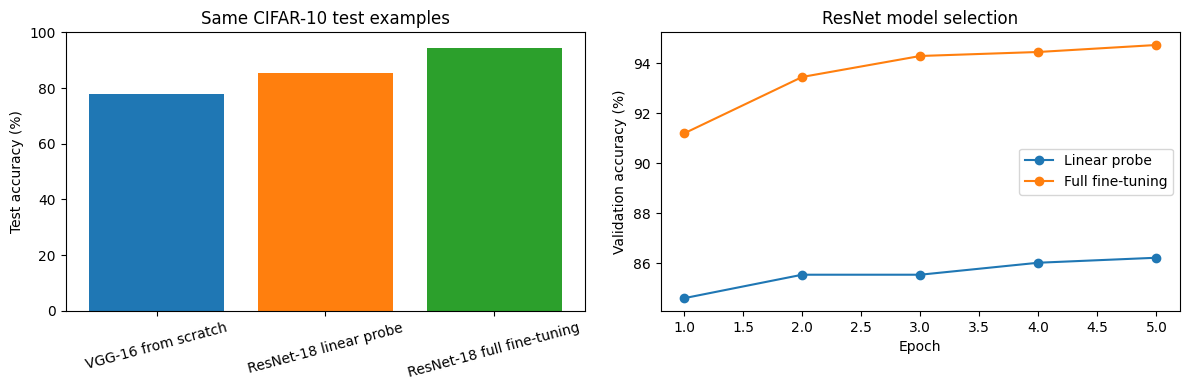

In [32]:
comparison = pd.DataFrame([vgg_result, probe_result, finetune_result])
display(comparison.style.format({
    'Trainable parameters': '{:,}',
    'Best validation accuracy (%)': '{:.2f}',
    'Test accuracy (%)': '{:.2f}',
    'Training seconds': '{:.1f}',
}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison['Experiment'], comparison['Test accuracy (%)'],
            color=['tab:blue', 'tab:orange', 'tab:green'])
axes[0].set_ylim(0, 100)
axes[0].set_ylabel('Test accuracy (%)')
axes[0].tick_params(axis='x', labelrotation=15)
axes[0].set_title('Same CIFAR-10 test examples')
for label, history in [('Linear probe', probe_history), ('Full fine-tuning', finetune_history)]:
    axes[1].plot([r['epoch'] for r in history],
                 [100 * r['val_accuracy'] for r in history], marker='o', label=label)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation accuracy (%)')
axes[1].set_title('ResNet model selection')
axes[1].legend()
fig.tight_layout()
plt.show()